## 0. About

Selamat datang di pembinaan bersama PRODIGI. Pada sesi ini, kita akan belajar cara melakukan *data preparation* terhadap *raw data* yang disediakan melalui tahap *data cleaning* dan *pre-processing* sedemikian sehingga data siap diinterpretasikan/dikonsumsi oleh model *machine learning*.

Identitas:
- Nama: Jefri Muhammad Rasyad
- NIM:

## 1.Import Library, Initial Setup Reproducibility, and Load Dataset

In [178]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import random
import os
from scipy import stats
from sklearn.model_selection import train_test_split

# ignore warning
import warnings
warnings.filterwarnings('ignore')

In [179]:
SEED = 42
def set_reproducibility(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
set_reproducibility(SEED)

In [ ]:
df = pd.read_csv(None)

## 2. Exploratory Data Analysis

### 2.1 Initial Data Inspection

In [181]:
# preview lima sampel data teratas
df.head()

,id,join_date,city,annual_income,debt_to_income_ratio,monthly_income,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,0,2023-12-01,Jakarta,"25,237.72",0.081,"2,103.14",627.00,2494,11.60,Male,Married,High School,Employed,Other,D5,1.00
1,1,2023-12-01,Surabaya,NaN,0.09,NaN,NaN,1123,12.56,Female,Single,NaN,NaN,Education,C5,1.00
2,2,2023-12-01,Jakarta,NaN,bingung_isi_apa,NaN,NaN,6839,11.96,Female,Single,NaN,NaN,Debt consolidation,D1,1.00
3,3,2023-12-01,Surabaya,NaN,bingung_isi_apa,NaN,NaN,5560,15.81,Female,Married,NaN,NaN,Debt consolidation,C3,1.00
4,4,2023-12-01,Jakarta,"59,854.09",0.102,"4,987.84",724.00,4241,12.42,Female,Single,Bachelor's,Employed,Debt consolidation,C3,1.00


In [182]:
# ukuran dataset
df.shape

(32820, 16)

In [183]:
# informasi tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32820 entries, 0 to 32819
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    32820 non-null  int64  
 1   join_date             32820 non-null  object 
 2   city                  32820 non-null  object 
 3   annual_income         31179 non-null  float64
 4   debt_to_income_ratio  32820 non-null  object 
 5   monthly_income        31179 non-null  float64
 6   credit_score          31179 non-null  float64
 7   loan_amount           32820 non-null  object 
 8   interest_rate         32820 non-null  float64
 9   gender                32770 non-null  object 
 10  marital_status        32820 non-null  object 
 11  education_level       31179 non-null  object 
 12  employment_status     31179 non-null  object 
 13  loan_purpose          32820 non-null  object 
 14  grade_subgrade        32820 non-null  object 
 15  loan_paid_back     

Interpretasi: berdasarkan informasi di atas, kita dapat mengetahui ada kolom numerikal yang isi-nya ada satu atau lebih data bertipe string/object.

In [184]:
# klasifikasikan kolom berdasarkan tipe data-nya yang seharusnya
numerical = ['annual_income', 'debt_to_income_ratio', 'monthly_income', 'credit_score', 'loan_amount', 'interest_rate']
categorical = ['city', 'gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose', 'grade_subgrade', 'loan_paid_back']
time = ['join_date']

In [185]:
# cek ada berapa dan apa saja kategori unik di kolom kategorikal
for col in categorical:
    print(f"Kolom: {col}")
    print(f"jumlah kategori unik: {df[col].nunique()}")
    print(f"kategori unik: {df[col].unique()}")
    print("-" * 50)

Kolom: city
jumlah kategori unik: 6
kategori unik: ['Jakarta' 'Surabaya' 'Bandung' '  Bandung  ' '  Surabaya  ' '  Jakarta  ']
--------------------------------------------------
Kolom: gender
jumlah kategori unik: 5
kategori unik: ['Male' 'Female' 'Woman' nan 'Other' 'mAle']
--------------------------------------------------
Kolom: marital_status
jumlah kategori unik: 4
kategori unik: ['Married' 'Single' 'Divorced' 'Widowed']
--------------------------------------------------
Kolom: education_level
jumlah kategori unik: 5
kategori unik: ['High School' nan "Bachelor's" "Master's" 'Other' 'PhD']
--------------------------------------------------
Kolom: employment_status
jumlah kategori unik: 6
kategori unik: ['Employed' nan 'Retired' 'Unemployed' 'Self-employed' 'Student'
 'Employed_']
--------------------------------------------------
Kolom: loan_purpose
jumlah kategori unik: 8
kategori unik: ['Other' 'Education' 'Debt consolidation' 'Medical' 'Home' 'Car'
 'Business' 'Vacation']
------

In [186]:
# statistika deskriptif untuk variabel numerik
def describe_numerical_features_full(df, features):
    summary = []
    for col in features:
        s = pd.to_numeric(df[col], errors='coerce').dropna()
        summary.append({
            'feature': col,
            'mean': s.mean(),
            'median': s.median(),
            'mode': s.mode().iloc[0] if not s.mode().empty else None,
            'min': s.min(),
            'q1': s.quantile(0.25),
            'q3': s.quantile(0.75),
            'max': s.max(),
            'iqr': s.quantile(0.75) - s.quantile(0.25),
            'variance': s.var(),
            'std_dev': s.std(),
            'skewness': s.skew(),
            'kurtosis': s.kurt()
        })
    return pd.DataFrame(summary)

numerical_summary = describe_numerical_features_full(df, numerical)
numerical_summary

,feature,mean,median,mode,min,q1,q3,max,iqr,variance,std_dev,skewness,kurtosis
0,annual_income,"60,841.99","46,454.44","46,966.90","-169,700.08","28,003.82","61,100.13","38,065,394.00","33,096.31","289,780,367,803.91","538,312.52",46.44,"2,432.30"
1,debt_to_income_ratio,0.12,0.10,0.09,0.01,0.07,0.16,0.58,0.09,0.00,0.07,1.41,2.39
2,monthly_income,"5,075.69","3,873.04","3,913.91",508.36,"2,335.27","5,092.19","3,172,116.17","2,756.92","2,012,307,654.22","44,858.75",46.45,"2,432.41"
3,credit_score,680.91,682.00,678.00,431.00,647.00,719.00,849.00,72.00,"3,072.82",55.43,-0.20,0.13
4,loan_amount,"5,505.90","5,524.50","2,189.00","1,000.00","3,258.00","7,776.00","9,999.00","4,518.00","6,776,335.59","2,603.14",-0.01,-1.21
5,interest_rate,12.34,12.35,12.23,4.96,10.97,13.67,19.31,2.70,4.05,2.01,0.07,0.02


In [187]:
# statistika deskriptif untuk variabel kategorik
df_categorical_eda = df[categorical].copy()
df_categorical_eda['loan_paid_back'] = df_categorical_eda['loan_paid_back'].astype(str)
df_categorical_eda.describe()

,city,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
count,32820,32770,32820,31179,31179,32820,32820,32820
unique,6,5,4,5,6,8,30,2
top,Bandung,Female,Single,Bachelor's,Employed,Debt consolidation,C3,1.0
freq,11034,16864,15789,14778,23498,17936,3156,26217


In [188]:
# statistika deskriptif untuk variabel berbasis waktu (tanggal)
# format='mixed' agar Pandas otomatis menyesuaikan format tanggal yang berbeda
pd.to_datetime(df['join_date'], format='mixed').describe()

count                            32820
mean     2023-11-30 18:05:42.230347264
min                2023-01-12 00:00:00
25%                2023-12-01 00:00:00
50%                2023-12-01 00:00:00
75%                2023-12-01 00:00:00
max                2023-12-01 00:00:00
Name: join_date, dtype: object

### 2.2 Univariate Analysis

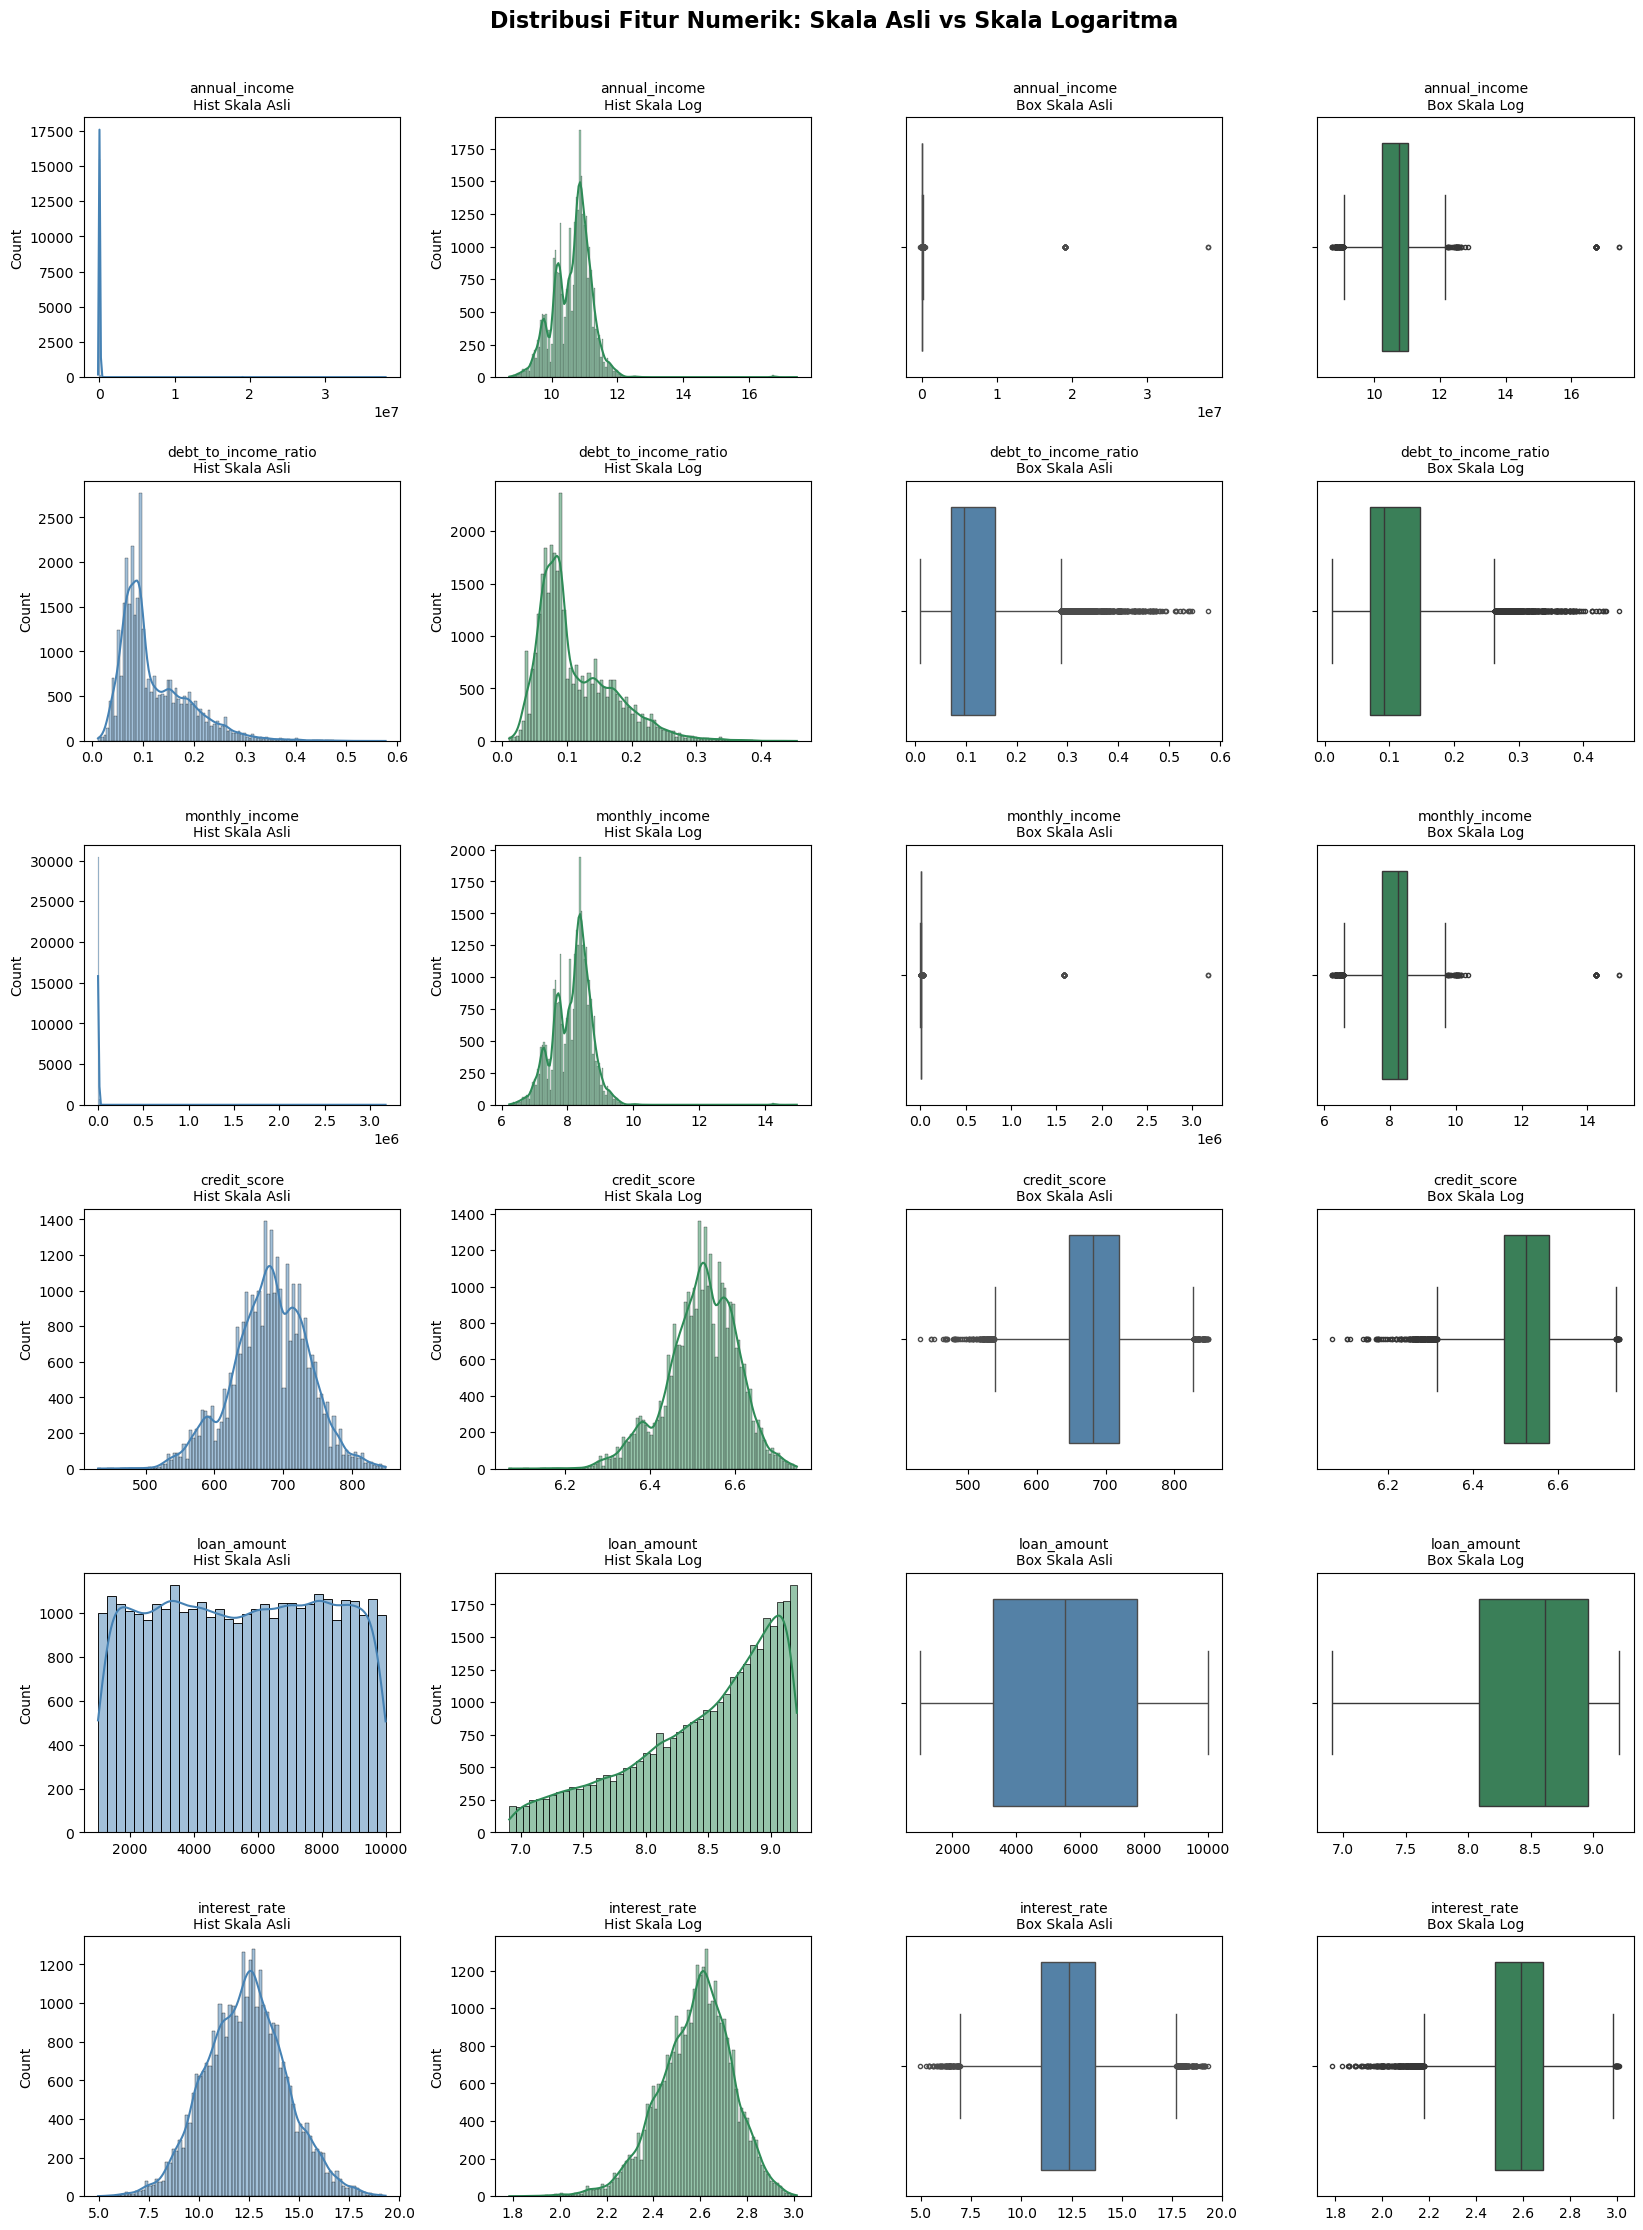

In [189]:
fig, axes = plt.subplots(nrows=len(numerical), ncols=4, figsize=(20, len(numerical) * 4.5))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

for i, col in enumerate(numerical):
    # Konversi sementara ke numerik agar string pengganggu tidak membuat error saat plotting
    data_cleaned = pd.to_numeric(df[col], errors='coerce')
    
    # log transform menggunakan data yang sudah bersih dari string
    data_asli = data_cleaned
    data_log = np.log1p(data_cleaned)
    
    # histogram: original scale
    sns.histplot(data_asli, kde=True, ax=axes[i, 0], color='steelblue')
    axes[i, 0].set_title(f'{col}\nHist Skala Asli', fontsize=10)
    
    # histogram: log scale
    sns.histplot(data_log, kde=True, ax=axes[i, 1], color='seagreen')
    axes[i, 1].set_title(f'{col}\nHist Skala Log', fontsize=10)
    
    # boxplot: original scale
    sns.boxplot(x=data_asli, ax=axes[i, 2], color='steelblue', fliersize=3)
    axes[i, 2].set_title(f'{col}\nBox Skala Asli', fontsize=10)
    
    # boxplot: log scale
    sns.boxplot(x=data_log, ax=axes[i, 3], color='seagreen', fliersize=3)
    axes[i, 3].set_title(f'{col}\nBox Skala Log', fontsize=10)

    # delete label on x-axis for clean visualization
    for j in range(4):
        axes[i, j].set_xlabel('')

fig.suptitle('Distribusi Fitur Numerik: Skala Asli vs Skala Logaritma', fontsize=16, fontweight='bold', y=0.92)
plt.show()

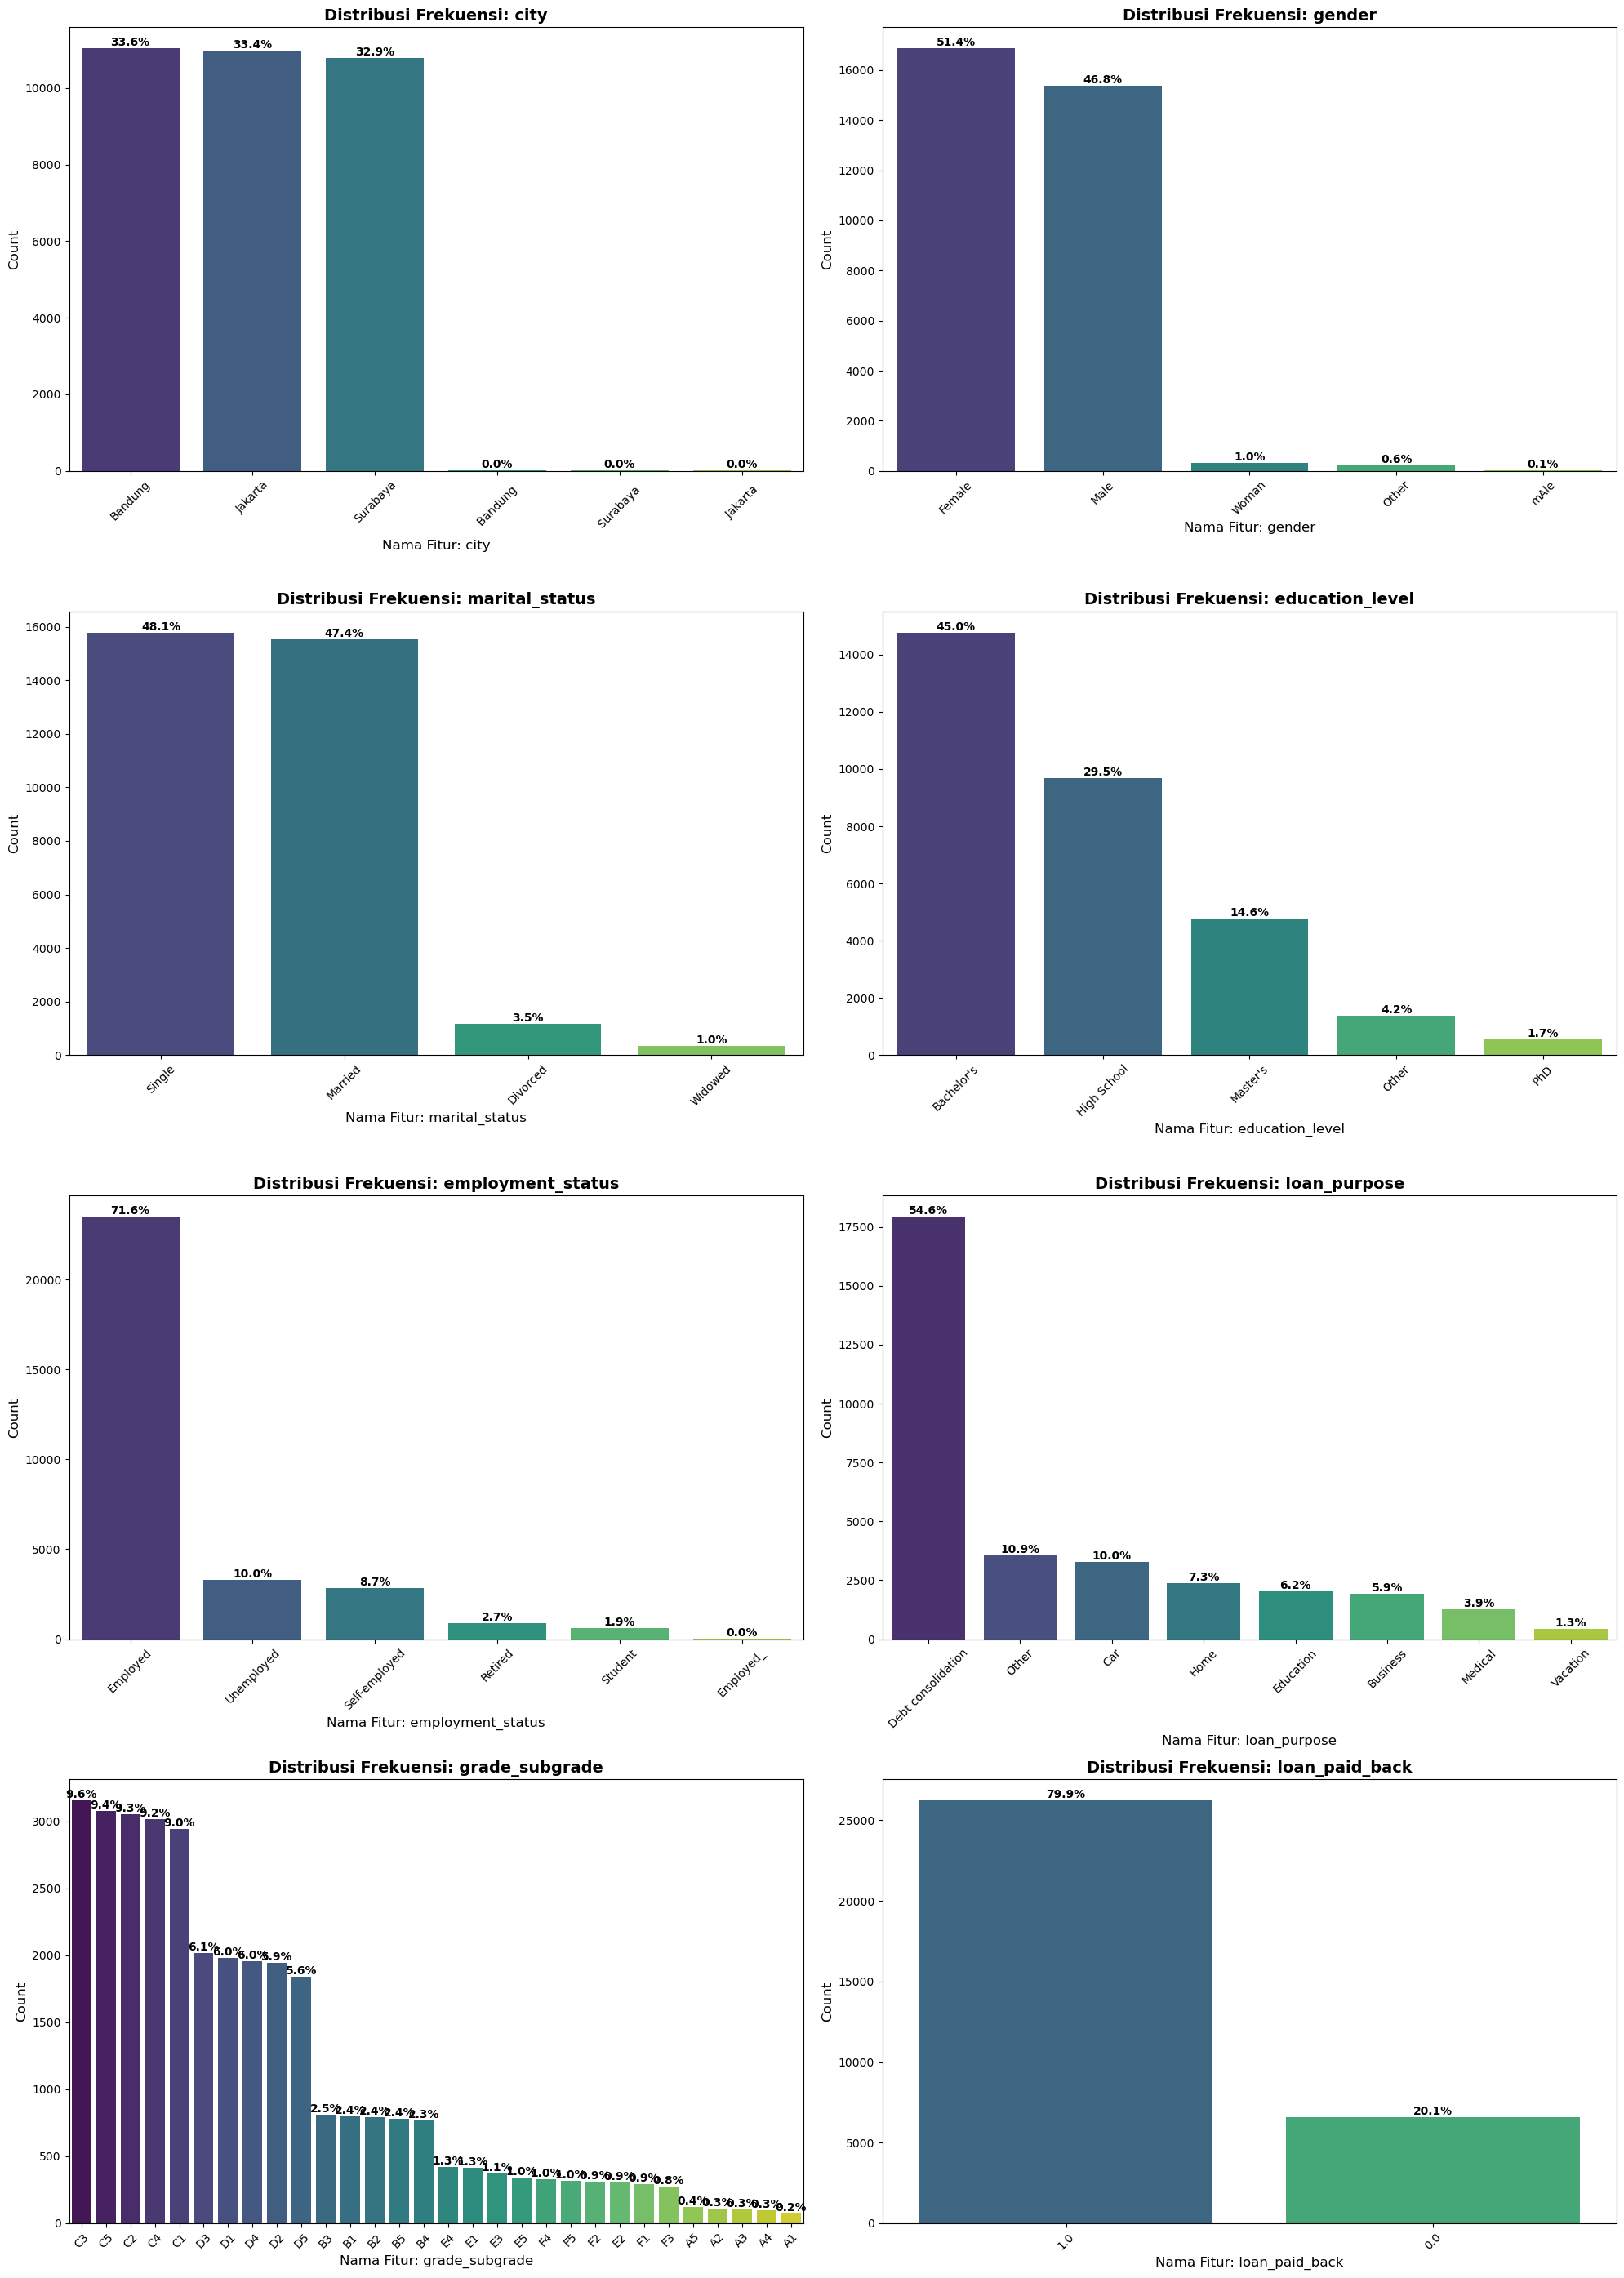

In [190]:
num_features = len(categorical)
nrows = (num_features + 1) // 2

# define figure menggunakan dimensi dinamis
fig, axes = plt.subplots(nrows=nrows, ncols=2, figsize=(20, nrows * 7))
axes = axes.flatten()

for i, col in enumerate(categorical):
    ax = axes[i]
    
    # Ambil urutan berdasarkan value_counts dari df_categorical_eda
    order = df_categorical_eda[col].value_counts().index
    
    # create countplot menggunakan df_categorical_eda
    sns.countplot(data=df_categorical_eda, x=col, ax=ax, palette='viridis', order=order)
    
    # customize label and title
    ax.set_title(f'Distribusi Frekuensi: {col}', fontsize=14, fontweight='bold')
    ax.set_xlabel(f'Nama Fitur: {col}', fontsize=12)
    ax.set_ylabel('Count', fontsize=12)
    
    # rotate x label agar teks kategori tidak saling bertumpuk
    ax.tick_params(axis='x', rotation=45)
    
    # add percentage on bars (menggunakan total baris data yang ada)
    total = len(df_categorical_eda)
    for p in ax.patches:
        height = p.get_height()
        if height > 0: # Hanya beri anotasi jika bar memiliki tinggi > 0
            percentage = f'{100 * height / total:.1f}%'
            x = p.get_x() + p.get_width() / 2
            y = height
            ax.annotate(percentage, (x, y), ha='center', va='bottom', fontsize=10, fontweight='bold')

# Jika ada sisa sumbu/axes grafik yang kosong (karena jumlah fitur ganjil), hapus dari visualisasi
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# adjust layout
plt.tight_layout()
plt.show()

In [191]:
# Menampilkan value_counts untuk setiap kolom kategorikal
for col in categorical:
    print(f"=== Value Counts Kolom: {col} ===")
    print(df_categorical_eda[col].value_counts(dropna=False))
    print("\n" + "="*40 + "\n")

=== Value Counts Kolom: city ===
city
Bandung         11034
Jakarta         10970
Surabaya        10786
  Bandung          16
  Surabaya          7
  Jakarta           7
Name: count, dtype: int64


=== Value Counts Kolom: gender ===
gender
Female    16864
Male      15362
Woman       314
Other       208
NaN          50
mAle         22
Name: count, dtype: int64


=== Value Counts Kolom: marital_status ===
marital_status
Single      15789
Married     15542
Divorced     1151
Widowed       338
Name: count, dtype: int64


=== Value Counts Kolom: education_level ===
education_level
Bachelor's     14778
High School     9696
Master's        4785
NaN             1641
Other           1376
PhD              544
Name: count, dtype: int64


=== Value Counts Kolom: employment_status ===
employment_status
Employed         23498
Unemployed        3297
Self-employed     2862
NaN               1641
Retired            879
Student            627
Employed_           16
Name: count, dtype: int64


=== Value C

In [192]:
# cek proporsi nilai hilang
df.isnull().sum()

id                         0
join_date                  0
city                       0
annual_income           1641
debt_to_income_ratio       0
monthly_income          1641
credit_score            1641
loan_amount                0
interest_rate              0
gender                    50
marital_status             0
education_level         1641
employment_status       1641
loan_purpose               0
grade_subgrade             0
loan_paid_back             0
dtype: int64

In [193]:
# cek proporsi outlier
def outliers_info_IQR(df, numerical_features, show_index=False):
    summary_list = []
    outlier_indices = {}
    for col in numerical_features:
        # Konversi sementara ke numerik agar string pengganggu otomatis menjadi NaN
        series = pd.to_numeric(df[col], errors='coerce').dropna()
        
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Cari index outlier menggunakan kondisi series yang sudah bersih
        # Menggunakan .loc bersama pd.to_numeric agar pencocokan index baris tetap akurat dengan df asli
        cleaned_col_series = pd.to_numeric(df[col], errors='coerce')
        outliers = df[(cleaned_col_series < lower_bound) | (cleaned_col_series > upper_bound)].index
        
        summary_list.append({
            "Variabel Numerik": col,
            "Q1": round(Q1, 2),
            "Q3": round(Q3, 2),
            "IQR": round(IQR, 2),
            "Lower Bound": round(lower_bound, 2),
            "Upper Bound": round(upper_bound, 2),
            "Total Outliers": len(outliers),
            "Percent Outliers (%)": round(len(outliers) / len(df) * 100, 2),
        })
        if show_index:
            outlier_indices[col] = outliers.tolist()
            
    summary_df = pd.DataFrame(summary_list)
    
    # better display
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 200)
    pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
    
    if show_index:
        return summary_df, outlier_indices
    else:
        return summary_df

# Jalankan fungsi menggunakan DataFrame 'df' dan list 'numerical'
outliers_summary = outliers_info_IQR(df, numerical, show_index=False)
outliers_summary

,Variabel Numerik,Q1,Q3,IQR,Lower Bound,Upper Bound,Total Outliers,Percent Outliers (%)
0,annual_income,"28,003.82","61,100.13","33,096.30","-21,640.63","110,744.59",833,2.54
1,debt_to_income_ratio,0.07,0.16,0.09,-0.06,0.29,893,2.72
2,monthly_income,"2,335.27","5,092.19","2,756.92","-1,800.11","9,227.57",815,2.48
3,credit_score,647.00,719.00,72.00,539.00,827.00,334,1.02
4,loan_amount,"3,258.00","7,776.00","4,518.00","-3,519.00","14,553.00",0,0.00
5,interest_rate,10.97,13.67,2.70,6.92,17.72,272,0.83


## 3. Pre-processing

### 3.1 Penyesuaian Isi dari Kolom Numerik yang Tidak Bertipe Data Numerik (string/object)

In [194]:
# ubah string/object non-numerik menjadi nilai kosong
df['debt_to_income_ratio'] = pd.to_numeric(df['debt_to_income_ratio'], errors='coerce')
df['loan_amount'] = pd.to_numeric(df['loan_amount'], errors='coerce')

# lalu untuk memastikan lebih lanjut, kita konversi ke float
df['debt_to_income_ratio'] = df['debt_to_income_ratio'].astype(float)
df['loan_amount'] = df['loan_amount'].astype(float)

### 3.2 Penyesuaian Nama Kategori Unik pada Kolom Kategorik

In [195]:
# Kolom 'city': Menghapus spasi liar (leading/trailing whitespace)
# '  Bandung' -> 'Bandung'
df['city'] = df['city'].str.strip()

# Kolom 'gender': Menyatukan penamaan yang maknanya sama & perbaikan typo
gender_mapping = {
    'Woman': 'Female',
    'mAle': 'Male',
    'Female': 'Female',
    'Male': 'Male',
    'Other': 'Other'
}
df['gender'] = df['gender'].map(gender_mapping)

# Kolom 'employment_status': Menghapus karakter typo (_) di akhir kata
df['employment_status'] = df['employment_status'].str.rstrip('_')

# verifikasi hasil
for col in ['city', 'gender', 'employment_status']:
    print(f"=== Value Counts Aktual Kolom: {col} ===")
    print(df[col].value_counts(dropna=False))
    print("-" * 40)

=== Value Counts Aktual Kolom: city ===
city
Bandung     11050
Jakarta     10977
Surabaya    10793
Name: count, dtype: int64
----------------------------------------
=== Value Counts Aktual Kolom: gender ===
gender
Female    17178
Male      15384
Other       208
NaN          50
Name: count, dtype: int64
----------------------------------------
=== Value Counts Aktual Kolom: employment_status ===
employment_status
Employed         23514
Unemployed        3297
Self-employed     2862
NaN               1641
Retired            879
Student            627
Name: count, dtype: int64
----------------------------------------


### 3.3 Penyesuaian Format Tanggal

In [196]:
df['join_date'] = pd.to_datetime(df['join_date'], format='mixed')

### 3.4 Data Splitting: Memastikan dapat proporsi 

In [197]:
# splitting langsung menjadi df_train dan df_test
df_train, df_test = train_test_split(
    df, 
    test_size=0.2,          # 20% untuk data test, 80% untuk data train
    random_state=SEED,        # Angka bebas agar hasil split selalu konsisten saat di-run ulang
    stratify=df['loan_paid_back'] # Menjaga proporsi kelas target tetap seimbang di train dan test
)

print(f"Ukuran Data Train : {df_train.shape}")
print(f"Ukuran Data Test  : {df_test.shape}\n")

print("=== Proporsi Target di Data Train (%) ===")
print(round(df_train['loan_paid_back'].value_counts(normalize=True) * 100, 2))

print("\n=== Proporsi Target di Data Test (%) ===")
print(round(df_test['loan_paid_back'].value_counts(normalize=True) * 100, 2))

Ukuran Data Train : (26256, 16)
Ukuran Data Test  : (6564, 16)

=== Proporsi Target di Data Train (%) ===
loan_paid_back
1.00   79.88
0.00   20.12
Name: proportion, dtype: float64

=== Proporsi Target di Data Test (%) ===
loan_paid_back
1.00   79.88
0.00   20.12
Name: proportion, dtype: float64


### 3.5 Handle Missing Values

In [198]:
# --- IMPUTASI FITUR NUMERIK (MEDIAN FROM TRAIN) ---
# annual_income
median_annual = df_train['annual_income'].median()
df_train['annual_income'] = df_train['annual_income'].fillna(median_annual)
df_test['annual_income'] = df_test['annual_income'].fillna(median_annual)

# monthly_income
median_monthly = df_train['monthly_income'].median()
df_train['monthly_income'] = df_train['monthly_income'].fillna(median_monthly)
df_test['monthly_income'] = df_test['monthly_income'].fillna(median_monthly)

# credit_score
median_credit = df_train['credit_score'].median()
df_train['credit_score'] = df_train['credit_score'].fillna(median_credit)
df_test['credit_score'] = df_test['credit_score'].fillna(median_credit)


# --- IMPUTASI FITUR KATEGORIK (MODE FROM TRAIN) ---
# gender
mode_gender = df_train['gender'].mode()[0]
df_train['gender'] = df_train['gender'].fillna(mode_gender)
df_test['gender'] = df_test['gender'].fillna(mode_gender)

# education_level
mode_edu = df_train['education_level'].mode()[0]
df_train['education_level'] = df_train['education_level'].fillna(mode_edu)
df_test['education_level'] = df_test['education_level'].fillna(mode_edu)

# employment_status
mode_employ = df_train['employment_status'].mode()[0]
df_train['employment_status'] = df_train['employment_status'].fillna(mode_employ)
df_test['employment_status'] = df_test['employment_status'].fillna(mode_employ)

In [199]:
# verifikasi
df_train.isnull().sum()

id                        0
join_date                 0
city                      0
annual_income             0
debt_to_income_ratio    525
monthly_income            0
credit_score              0
loan_amount              30
interest_rate             0
gender                    0
marital_status            0
education_level           0
employment_status         0
loan_purpose              0
grade_subgrade            0
loan_paid_back            0
dtype: int64

In [200]:
df_test.isnull().sum()

id                        0
join_date                 0
city                      0
annual_income             0
debt_to_income_ratio    124
monthly_income            0
credit_score              0
loan_amount              10
interest_rate             0
gender                    0
marital_status            0
education_level           0
employment_status         0
loan_purpose              0
grade_subgrade            0
loan_paid_back            0
dtype: int64

- Loh..., kok bisa `debt_to_income_ration` dan `loan_amount` masih kosong?
- JAWAB: ...?

In [201]:
# task: tangani nilai kosong yang tersisa pada kedua fitur numerik
None

### 3.6 Handle Outliers

In [202]:
# --- PERCENTILE CAPPING (1st & 99th PERCENTILE) ---

# annual_income
lower_annual = df_train['annual_income'].quantile(0.01)
upper_annual = df_train['annual_income'].quantile(0.99)

df_train['annual_income'] = df_train['annual_income'].clip(lower=lower_annual, upper=upper_annual)
df_test['annual_income'] = df_test['annual_income'].clip(lower=lower_annual, upper=upper_annual)

# monthly_income
lower_monthly = df_train['monthly_income'].quantile(0.01)
upper_monthly = df_train['monthly_income'].quantile(0.99)
df_train['monthly_income'] = df_train['monthly_income'].clip(lower=lower_monthly, upper=upper_monthly)
df_test['monthly_income'] = df_test['monthly_income'].clip(lower=lower_monthly, upper=upper_monthly)

# credit_score
lower_credit = df_train['credit_score'].quantile(0.01)
upper_credit = df_train['credit_score'].quantile(0.99)
df_train['credit_score'] = df_train['credit_score'].clip(lower=lower_credit, upper=upper_credit)
df_test['credit_score'] = df_test['credit_score'].clip(lower=lower_credit, upper=upper_credit)

# loan_amount
lower_loan = df_train['loan_amount'].quantile(0.01)
upper_loan = df_train['loan_amount'].quantile(0.99)
df_train['loan_amount'] = df_train['loan_amount'].clip(lower=lower_loan, upper=upper_loan)
df_test['loan_amount'] = df_test['loan_amount'].clip(lower=lower_loan, upper=upper_loan)

# interest_rate
lower_interest = df_train['interest_rate'].quantile(0.01)
upper_interest = df_train['interest_rate'].quantile(0.99)
df_train['interest_rate'] = df_train['interest_rate'].clip(lower=lower_interest, upper=upper_interest)
df_test['interest_rate'] = df_test['interest_rate'].clip(lower=lower_interest, upper=upper_interest)

# debt_to_income_ratio
lower_dti = df_train['debt_to_income_ratio'].quantile(0.01)
upper_dti = df_train['debt_to_income_ratio'].quantile(0.99)
df_train['debt_to_income_ratio'] = df_train['debt_to_income_ratio'].clip(lower=lower_dti, upper=upper_dti)
df_test['debt_to_income_ratio'] = df_test['debt_to_income_ratio'].clip(lower=lower_dti, upper=upper_dti)

### 3.7 Handle Illogical Numerical Column

In [203]:
# check for value < 0, cap to 0

print("=== JUMLAH NILAI NEGATIF DI DF_TRAIN ===")
print(f"annual_income         : {(df_train['annual_income'] < 0).sum()}")
print(f"monthly_income        : {(df_train['monthly_income'] < 0).sum()}")
print(f"credit_score          : {(df_train['credit_score'] < 0).sum()}")
print(f"loan_amount           : {(df_train['loan_amount'] < 0).sum()}")
print(f"interest_rate         : {(df_train['interest_rate'] < 0).sum()}")
print(f"debt_to_income_ratio  : {(df_train['debt_to_income_ratio'] < 0).sum()}")

print("\n=== JUMLAH NILAI NEGATIF DI DF_TEST ===")
print(f"annual_income         : {(df_test['annual_income'] < 0).sum()}")
print(f"monthly_income        : {(df_test['monthly_income'] < 0).sum()}")
print(f"credit_score          : {(df_test['credit_score'] < 0).sum()}")
print(f"loan_amount           : {(df_test['loan_amount'] < 0).sum()}")
print(f"interest_rate         : {(df_test['interest_rate'] < 0).sum()}")
print(f"debt_to_income_ratio  : {(df_test['debt_to_income_ratio'] < 0).sum()}")

=== JUMLAH NILAI NEGATIF DI DF_TRAIN ===
annual_income         : 0
monthly_income        : 0
credit_score          : 0
loan_amount           : 0
interest_rate         : 0
debt_to_income_ratio  : 0

=== JUMLAH NILAI NEGATIF DI DF_TEST ===
annual_income         : 0
monthly_income        : 0
credit_score          : 0
loan_amount           : 0
interest_rate         : 0
debt_to_income_ratio  : 0


In [ ]:
# task: tangani nilai tersebut agar logis (andalkan capping atau map ke nilai tertentu selagi menurut Anda logis)
None

argumen: ...

### 3.8 Feature Engineering

In [205]:
# FEATURE CREATION AND EXTRACTION

df_train['loan_to_income_ratio'] = df_train['loan_amount'] / df_train['annual_income']
df_test['loan_to_income_ratio'] = df_test['loan_amount'] / df_test['annual_income']

# Estimasi Sisa Pendapatan Bulanan (Disposable Income Estimate)
# Mengukur sisa uang bulanan setelah dikurangi estimasi bayar utang (menggunakan DTI)
# Formula: Monthly Income * (1 - Debt-to-Income Ratio)
df_train['disposable_income'] = df_train['monthly_income'] * (1 - df_train['debt_to_income_ratio'])
df_test['disposable_income'] = df_test['monthly_income'] * (1 - df_test['debt_to_income_ratio'])

# Ekstraksi Fitur Komponen Waktu (Tahun & Bulan)
# Mengambil tahun dan bulan bergabung untuk melihat tren makroekonomi/musiman
df_train['join_year'] = df_train['join_date'].dt.year
df_train['join_month'] = df_train['join_date'].dt.month

df_test['join_year'] = df_test['join_date'].dt.year
df_test['join_month'] = df_test['join_date'].dt.month

# Perhitungan Durasi Menjadi Anggota (Dalam Bulan)
# Menghitung seberapa lama nasabah telah bergabung hingga tahun saat ini (2026)
current_year = 2026
df_train['membership_months'] = (current_year - df_train['join_date'].dt.year) * 12 + (12 - df_train['join_date'].dt.month)
df_test['membership_months'] = (current_year - df_test['join_date'].dt.year) * 12 + (12 - df_test['join_date'].dt.month)

# Drop kolom 'join_date' karena seluruh esensi informasinya sudah diekstrak ke fitur baru
df_train = df_train.drop(columns=['join_date'])
df_test = df_test.drop(columns=['join_date'])

In [206]:
# CEK VALUE COUNTS FITUR KATEGORIKAL UNTUK DAPAT MENENTUKAN DENGAN LEBIH VALID INGIN ENCODE DENGAN METODE APA

for col in ['city', 'gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose', 'grade_subgrade']:
    print(f"=== VALUE COUNTS: {col} ===")
    print(df_train[col].value_counts(dropna=False))
    print("\n" + "="*40 + "\n")

=== VALUE COUNTS: city ===
city
Bandung     8788
Jakarta     8764
Surabaya    8704
Name: count, dtype: int64


=== VALUE COUNTS: gender ===
gender
Female    13768
Male      12322
Other       166
Name: count, dtype: int64


=== VALUE COUNTS: marital_status ===
marital_status
Single      12646
Married     12439
Divorced      908
Widowed       263
Name: count, dtype: int64


=== VALUE COUNTS: education_level ===
education_level
Bachelor's     13087
High School     7798
Master's        3837
Other           1093
PhD              441
Name: count, dtype: int64


=== VALUE COUNTS: employment_status ===
employment_status
Employed         20182
Unemployed        2600
Self-employed     2268
Retired            702
Student            504
Name: count, dtype: int64


=== VALUE COUNTS: loan_purpose ===
loan_purpose
Debt consolidation    14378
Other                  2859
Car                    2575
Home                   1944
Education              1623
Business               1511
Medical              

In [207]:
# CATEGORICAL FEATURE ENCODING

# === ONE HOT ECODING ===
ohe_columns = ['city', 'gender', 'marital_status', 'employment_status', 'loan_purpose']
df_train = pd.get_dummies(df_train, columns=ohe_columns, drop_first=True, dtype=int)
df_test = pd.get_dummies(df_test, columns=ohe_columns, drop_first=True, dtype=int)

# pencegahan Perbedaan Kolom Train & Test
# Memastikan urutan dan jumlah kolom di df_test sama persis dengan df_train
# Ambil struktur kolom dari df_train (kecuali target dan identifier waktu)
df_test = df_test.reindex(columns=df_train.columns, fill_value=0)


# === ORDINAL ENCODING ===
# ODE: Education Level
edu_mapping = {
    'Other': 0,
    'High School': 1,
    'Bachelor\'s': 2,
    'Master\'s': 3,
    'PhD': 4
}
df_train['education_level_encoded'] = df_train['education_level'].map(edu_mapping)
df_test['education_level_encoded'] = df_test['education_level'].map(edu_mapping)

# ODE: grade_subgrade
grade_categories = sorted(df_train['grade_subgrade'].dropna().unique())
grade_mapping = {grade: idx for idx, grade in enumerate(grade_categories)}
df_train['grade_subgrade_encoded'] = df_train['grade_subgrade'].map(grade_mapping)
df_test['grade_subgrade_encoded'] = df_test['grade_subgrade'].map(grade_mapping)

# drop kolom asli setelah berhasil di-encode secara ODE
df_train = df_train.drop(columns=['education_level', 'grade_subgrade'])
df_test = df_test.drop(columns=['education_level', 'grade_subgrade'])


### 3.9 Verifikasi Akhir

- Bertipe data numerik semua.
- Tidak ada nilai kosong.
- Kolom yang dibutuhkan ada (fitur, target, etc).

In [208]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26256 entries, 6672 to 13648
Data columns (total 33 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id                               26256 non-null  int64  
 1   annual_income                    26256 non-null  float64
 2   debt_to_income_ratio             25731 non-null  float64
 3   monthly_income                   26256 non-null  float64
 4   credit_score                     26256 non-null  float64
 5   loan_amount                      26226 non-null  float64
 6   interest_rate                    26256 non-null  float64
 7   loan_paid_back                   26256 non-null  float64
 8   loan_to_income_ratio             26226 non-null  float64
 9   disposable_income                25731 non-null  float64
 10  join_year                        26256 non-null  int32  
 11  join_month                       26256 non-null  int32  
 12  membership_months   